# 01. Preparación, Limpieza e Ingeniería de Características — Unidad 2
**Proyecto:** Sistema de IA para Detección y Priorización de Fraude (IBM TabFormer)  
**Unidad 2:** Modelos Avanzados Supervisados y No Supervisados  
**Entorno:** Python 3.12 | Polars | scikit-learn | Matplotlib

---

### Objetivos del Notebook:
1. Cargar las particiones temporales procesadas (`train_split.parquet` y `test_split.parquet`).
2. Auditar exhaustivamente tipos de datos, consistencia, valores ausentes y prevalencia de fraude.
3. Construir variables derivadas avanzadas mediante **Ingeniería de Características sin fuga temporal**:
   - **Temporales:** `hour`, `minute`, `day_of_week`, `is_weekend`, `is_night`.
   - **Cíclicas horarias:** $	ext{hour\_sin} = \sin(2\pi \cdot 	ext{hour}/24)$ y $	ext{hour\_cos} = \cos(2\pi \cdot 	ext{hour}/24)$ para preservar la continuidad de las 23:59 a las 00:00.
   - **Monetaria:** $	ext{amount\_log} = \log(1 + 	ext{Amount})$ para estabilizar la asimetría severa de importes y comprimir colas pesadas de outliers.
   - **Categóricas:** `Use Chip`, macro-sectores `mcc_category` (estándar ISO 18245) e indicador de canal `is_online` derivado de `Merchant State == 'ONLINE'`.
4. Demostrar y documentar formalmente el **Esquema de Validación Cruzada Temporal (`TimeSeriesSplit` con 5 folds)** sobre el período de desarrollo (2017–2018).
5. Auditar y verificar el reporte de particiones en `data/processed/resumen_particiones.csv`.
6. Guardar los datasets enriquecidos de la Unidad 2 para los notebooks de modelado y clustering.


In [1]:
import sys
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR
while not (PROJECT_ROOT / "notebooks").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from notebooks._comun.config import (
    TRAIN_DATA_FILE,
    TEST_DATA_FILE,
    PARTITIONS_SUMMARY_FILE,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
    NUMERICAL_FEATURES_U2,
    CATEGORICAL_FEATURES_U2,
    SELECTED_FEATURES_U2,
)
from notebooks._comun.data_utils import (
    categorize_mcc_expr,
    add_u2_engineered_features,
)
print(f"Raíz del proyecto: {PROJECT_ROOT}")


Raíz del proyecto: /home/glender/ProyectosUNi/iaupeu


In [2]:
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit

# Cargar particiones temporales
train_raw = pl.read_parquet(TRAIN_DATA_FILE)
test_raw = pl.read_parquet(TEST_DATA_FILE)

print("=== Particiones Cargadas ===")
print(f"Train (Desarrollo 2017-2018): {train_raw.shape[0]:,} transacciones | Fraudes: {train_raw['is_fraud'].sum():,} ({train_raw['is_fraud'].mean()*100:.4f}%)")
print(f"Test  (Prueba Final 2019):    {test_raw.shape[0]:,} transacciones | Fraudes: {test_raw['is_fraud'].sum():,} ({test_raw['is_fraud'].mean()*100:.4f}% prevalencia natural)")


=== Particiones Cargadas ===
Train (Desarrollo 2017-2018): 252,670 transacciones | Fraudes: 2,670 (1.0567%)
Test  (Prueba Final 2019):    1,639,673 transacciones | Fraudes: 2,033 (0.1240% prevalencia natural)


## 1. Verificación del Resumen de Particiones
Auditemos el archivo central `data/processed/resumen_particiones.csv` que detalla los tamaños, períodos y prevalencias.


In [3]:
resumen_df = pl.read_csv(PARTITIONS_SUMMARY_FILE)
print("Resumen Oficial de Particiones del Proyecto:")
print(resumen_df)


Resumen Oficial de Particiones del Proyecto:
shape: (5, 6)
┌────────────────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┐
│ particion      ┆ periodo        ┆ total_registro ┆ total_fraudes ┆ prevalencia_f ┆ descripcion   │
│ ---            ┆ ---            ┆ s              ┆ ---           ┆ raude_pct     ┆ ---           │
│ str            ┆ str            ┆ ---            ┆ i64           ┆ ---           ┆ str           │
│                ┆                ┆ i64            ┆               ┆ f64           ┆               │
╞════════════════╪════════════════╪════════════════╪═══════════════╪═══════════════╪═══════════════╡
│ Universo Crudo ┆ 1991 - 2020    ┆ 24386900       ┆ 29757         ┆ 0.122         ┆ Dataset       │
│ Total          ┆                ┆                ┆               ┆               ┆ original      │
│                ┆                ┆                ┆               ┆               ┆ completo de   │
│                ┆              

## 2. Construcción de Variables Derivadas (Feature Engineering)
Construimos las variables que alimentarán los modelos supervisados y el clustering de la Unidad 2:
1. **Transformación Cíclica:** La hora del día (0–23) es una magnitud circular. Aplicar seno y coseno asegura que la distancia entre las 23:00 y las 00:00 sea de 1 hora, no de 23.
2. **Transformación Logarítmica:** `amount_log = log(Amount + 1)` estabiliza la varianza de los importes bancarios, permitiendo que algoritmos basados en distancias (KNN, K-Means) o funciones de coste (Regresión Logística, Redes) no se desestabilicen por transacciones atípicas de miles de dólares.
3. **Indicador de Canal Online:** Derivamos `is_online` a partir de `Merchant State == 'ONLINE'`.
4. **Macro-categorías MCC:** Agrupamos los códigos comerciales en sectores de consumo interpretables (ISO 18245).


In [4]:
# Aplicar enriquecimiento de MCC y features U2
train_u2 = train_raw.with_columns(categorize_mcc_expr("MCC"))
train_u2 = add_u2_engineered_features(train_u2)

test_u2 = test_raw.with_columns(categorize_mcc_expr("MCC"))
test_u2 = add_u2_engineered_features(test_u2)

print("Esquema de variables generadas para la Unidad 2:")
print(f"Numéricas ({len(NUMERICAL_FEATURES_U2)}):", NUMERICAL_FEATURES_U2)
print(f"Categóricas ({len(CATEGORICAL_FEATURES_U2)}):", CATEGORICAL_FEATURES_U2)
print(f"Total predictores:", len(SELECTED_FEATURES_U2))

print("\nMuestra de las primeras 5 filas enriquecidas:")
print(train_u2.select(SELECTED_FEATURES_U2 + ["is_fraud"]).head(5))


Esquema de variables generadas para la Unidad 2:
Numéricas (7): ['amount_log', 'hour_sin', 'hour_cos', 'minute', 'day_of_week', 'is_weekend', 'is_night']
Categóricas (3): ['Use Chip', 'mcc_category', 'is_online']
Total predictores: 10

Muestra de las primeras 5 filas enriquecidas:
shape: (5, 11)
┌────────────┬──────────┬──────────┬────────┬───┬─────────────┬─────────────┬───────────┬──────────┐
│ amount_log ┆ hour_sin ┆ hour_cos ┆ minute ┆ … ┆ Use Chip    ┆ mcc_categor ┆ is_online ┆ is_fraud │
│ ---        ┆ ---      ┆ ---      ┆ ---    ┆   ┆ ---         ┆ y           ┆ ---       ┆ ---      │
│ f64        ┆ f64      ┆ f64      ┆ i32    ┆   ┆ str         ┆ ---         ┆ str       ┆ i32      │
│            ┆          ┆          ┆        ┆   ┆             ┆ str         ┆           ┆          │
╞════════════╪══════════╪══════════╪════════╪═══╪═════════════╪═════════════╪═══════════╪══════════╡
│ 4.57502    ┆ 0.0      ┆ 1.0      ┆ 3      ┆ … ┆ Chip        ┆ Misc_Retail ┆ IN_PERSON ┆ 0      

## 3. Inspección Visual de Características Cíclicas y Monetarias
Visualizamos la transformación cíclica de la hora y la estabilización de importes.


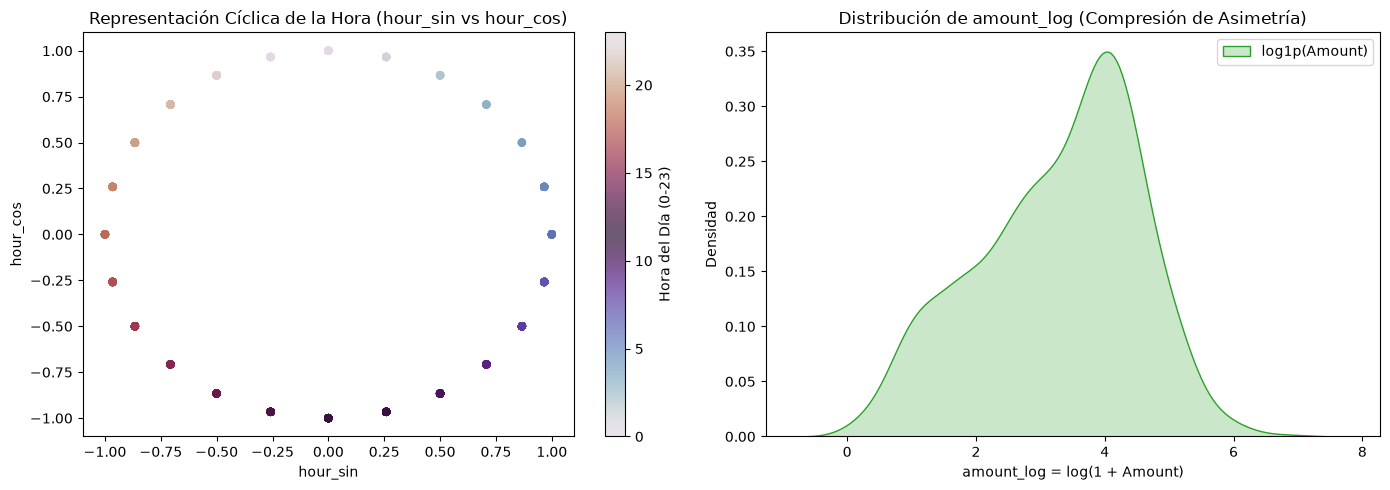

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Transformación cíclica horaria
df_sample_plot = train_u2.sample(n=1000, seed=RANDOM_STATE).to_pandas()
scatter = ax1.scatter(df_sample_plot["hour_sin"], df_sample_plot["hour_cos"],
                      c=df_sample_plot["hour"], cmap="twilight", alpha=0.7, edgecolors="none")
ax1.set_title("Representación Cíclica de la Hora (hour_sin vs hour_cos)")
ax1.set_xlabel("hour_sin")
ax1.set_ylabel("hour_cos")
plt.colorbar(scatter, ax=ax1, label="Hora del Día (0-23)")

# 2. Distribución de amount_log vs Amount
sns.kdeplot(df_sample_plot["amount_log"], fill=True, color="#2ca02c", ax=ax2, label="log1p(Amount)")
ax2.set_title("Distribución de amount_log (Compresión de Asimetría)")
ax2.set_xlabel("amount_log = log(1 + Amount)")
ax2.set_ylabel("Densidad")
ax2.legend()

plt.tight_layout()
plt.show()


## 4. Esquema de Validación Cruzada Temporal (`TimeSeriesSplit` 5-Folds)
Para evaluar honestamente los modelos supervisados sin incurrir en fuga temporal hacia el futuro, dividimos el conjunto de desarrollo (2017–2018) ordenado cronológicamente mediante **5 particiones temporales progresivas**:
- En cada iteración $k$, el modelo se entrena **únicamente con el pasado** y se valida sobre el bloque temporal inmediato posterior.


In [6]:
# Demostración formal de los 5 Folds
tscv = TimeSeriesSplit(n_splits=5)
X_demo = train_u2.select(SELECTED_FEATURES_U2).to_pandas()
y_demo = train_u2["is_fraud"].to_numpy()

print("=== Configuración de Folds de Validación Cruzada Temporal ===")
fold_info = []
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_demo), 1):
    y_tr_fold = y_demo[train_idx]
    y_vl_fold = y_demo[val_idx]
    
    info = {
        "Fold": fold,
        "Train_Size": len(train_idx),
        "Train_Frauds": int(np.sum(y_tr_fold)),
        "Train_Prev_%": round(float(np.mean(y_tr_fold) * 100), 4),
        "Val_Size": len(val_idx),
        "Val_Frauds": int(np.sum(y_vl_fold)),
        "Val_Prev_%": round(float(np.mean(y_vl_fold) * 100), 4),
    }
    fold_info.append(info)
    print(f"Fold {fold}: Train={info['Train_Size']:,} (Fraudes: {info['Train_Frauds']:,} - {info['Train_Prev_%']}%) | "
          f"Val={info['Val_Size']:,} (Fraudes: {info['Val_Frauds']:,} - {info['Val_Prev_%']}%)")

df_folds = pd.DataFrame(fold_info)


=== Configuración de Folds de Validación Cruzada Temporal ===
Fold 1: Train=42,115 (Fraudes: 307 - 0.729%) | Val=42,111 (Fraudes: 435 - 1.033%)
Fold 2: Train=84,226 (Fraudes: 742 - 0.881%) | Val=42,111 (Fraudes: 498 - 1.1826%)
Fold 3: Train=126,337 (Fraudes: 1,240 - 0.9815%) | Val=42,111 (Fraudes: 362 - 0.8596%)
Fold 4: Train=168,448 (Fraudes: 1,602 - 0.951%) | Val=42,111 (Fraudes: 489 - 1.1612%)
Fold 5: Train=210,559 (Fraudes: 2,091 - 0.9931%) | Val=42,111 (Fraudes: 579 - 1.3749%)


## 5. Exportación de Datasets Enriquecidos para la Unidad 2
Guardamos `train_u2.parquet` y `test_u2.parquet` en `data/processed/` para uso directo en `comparacion_modelos_unidad2.ipynb` y `kmeans_y_priorizacion_unidad2.ipynb`.


In [7]:
TRAIN_U2_FILE = PROCESSED_DATA_DIR / "train_u2.parquet"
TEST_U2_FILE = PROCESSED_DATA_DIR / "test_u2.parquet"

train_u2.write_parquet(TRAIN_U2_FILE, compression="snappy")
test_u2.write_parquet(TEST_U2_FILE, compression="snappy")

print(f"Dataset de desarrollo enriquecido guardado en: {TRAIN_U2_FILE} ({train_u2.shape[0]:,} filas)")
print(f"Dataset de prueba enriquecido guardado en:       {TEST_U2_FILE} ({test_u2.shape[0]:,} filas)")


Dataset de desarrollo enriquecido guardado en: /home/glender/ProyectosUNi/iaupeu/data/processed/train_u2.parquet (252,670 filas)
Dataset de prueba enriquecido guardado en:       /home/glender/ProyectosUNi/iaupeu/data/processed/test_u2.parquet (1,639,673 filas)
